# 13 – Ridge Regression

## Introduction

Ordinary Least Squares (OLS) estimates regression coefficients by minimizing the sum of squared residuals. However, in the presence of multicollinearity or an ill-conditioned design matrix, OLS coefficient estimates may become sensitive to small changes in the input data.

Ridge Regression addresses this issue by introducing an L2 regularization penalty into the least-squares objective function.

The objective of this experiment is to:

- Implement Ridge Regression using NumPy.
- Standardize the predictor variables before regularization.
- Examine the effect of regularization on coefficient estimates.
- Compare Ridge Regression with the revised OLS model.
- Evaluate the model using standard regression metrics.
- Examine the numerical properties of the regularized system.

The regularization parameter is denoted by λ (lambda). An initial value of λ = 1.0 is used for this experiment. The optimal value will be investigated separately through Ridge Trace analysis and k-fold cross-validation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

np.set_printoptions(precision=6, suppress=True)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.6f}")

sns.set_theme(style="whitegrid")

In [3]:
results = Path("../../results/implementation")

figures = results / "figures"
tables = results / "tables"

In [4]:
df = pd.read_csv("../../data/processed/real_estate_data_updated.csv")
df.head()

,X1 transaction year,X1 transaction month,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,2012,December,32.000000,84.878820,10,24.982980,121.540240,37.900000
1,2012,December,19.500000,306.594700,9,24.980340,121.539510,42.200000
2,2013,August,13.300000,561.984500,5,24.987460,121.543910,47.300000
3,2013,July,13.300000,561.984500,5,24.987460,121.543910,54.800000
4,2012,November,5.000000,390.568400,5,24.979370,121.542450,43.100000


In [5]:
numerical_features = [
    "X2 house age",
    "X3 distance to the nearest MRT station",
    "X4 number of convenience stores",
    "X5 latitude",
    "X6 longitude"
]

categorical_features = [
    "X1 transaction month"
]

target_column = "Y house price of unit area"

X_numerical = df[numerical_features].copy()

X_categorical = pd.get_dummies(
    df[categorical_features],
    drop_first=True,
    dtype=float
)

X = pd.concat(
    [X_numerical, X_categorical],
    axis=1
)

y = df[target_column].to_numpy(dtype=float)

feature_names = X.columns.tolist()

X = X.to_numpy(dtype=float)

print("Predictor matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("Number of predictors:", len(feature_names))

Predictor matrix shape: (414, 16)
Target vector shape: (414,)
Number of predictors: 16


In [7]:
x_design = np.column_stack([
    np.ones(X.shape[0]),
    X
])

design_feature_names = ["Intercept"] + feature_names

print("Design matrix shape:", x_design.shape)
print("Target vector shape:", y.shape)

print("All observations and values verified.")

Design matrix shape: (414, 17)
Target vector shape: (414,)
All observations and values verified.


In [9]:
# standardized predictors

X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0, ddof=0)

if np.any(X_std == 0):
    raise ValueError("At least one predictor has zero variance.")

X_standardized = (X - X_mean) / X_std

x_standardized_design = np.column_stack([
    np.ones(X_standardized.shape[0]),
    X_standardized
])

print("Standardization completed.")

print("Standardized predictor means:")
print(np.round(X_standardized.mean(axis=0), 6))

print("\nStandardized predictor standard deviations:")
print(np.round(X_standardized.std(axis=0), 6))

print("\nStandardized design matrix shape:")
print(x_standardized_design.shape)

Standardization completed.
Standardized predictor means:
[-0. -0. -0.  0. -0. -0. -0. -0.  0.  0.  0.  0. -0. -0.  0.  0.]

Standardized predictor standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Standardized design matrix shape:
(414, 17)


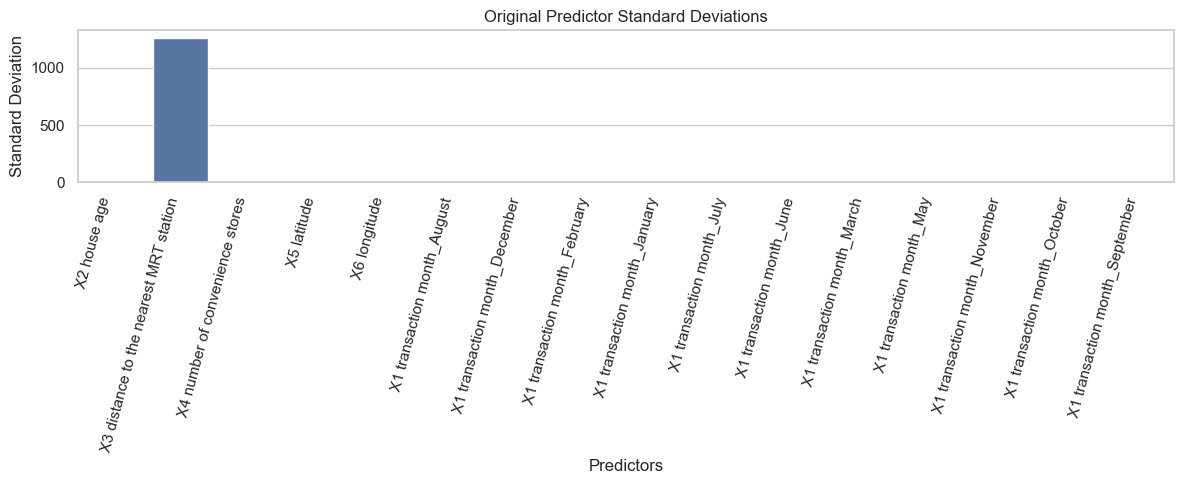

In [11]:
# visualize predictor scales

original_scales = pd.DataFrame({
    "Feature": feature_names,
    "Original Standard Deviation": X_std
})

plt.figure(figsize=(12, 5))

sns.barplot(
    data=original_scales,
    x="Feature",
    y="Original Standard Deviation"
)

plt.xticks(rotation=75, ha="right")
plt.title("Original Predictor Standard Deviations")
plt.xlabel("Predictors")
plt.ylabel("Standard Deviation")
plt.tight_layout()

plt.savefig(
    figures / "ridge_original_predictor_scales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 2. Ridge Regression Formulation

Ridge Regression modifies the OLS objective function by introducing an L2 penalty on the regression coefficients.

The objective function is:

\[
J(\beta) =
\|y-X\beta\|_2^2
+
\lambda\|\beta\|_2^2
\]

The corresponding Ridge estimator is:

\[
\hat{\beta}_{ridge}
=
(X^TX+\lambda I)^{-1}X^Ty
\]

For this experiment, the predictors are standardized before estimation.

An intercept is included in the model but is not penalized. Therefore, the regularization matrix is modified so that its intercept entry is zero.

The resulting estimator is:

\[
\hat{\beta}_{ridge}
=
(X_s^TX_s+\lambda P)^{-1}X_s^Ty
\]

where \(X_s\) is the standardized design matrix and \(P\) is the penalty matrix:

\[
P =
\begin{bmatrix}
0 & 0 & \cdots & 0\\
0 & 1 & \cdots & 0\\
\vdots & \vdots & \ddots & \vdots\\
0 & 0 & \cdots & 1
\end{bmatrix}
\]

The intercept is therefore excluded from the regularization penalty.

In [12]:
# define regularization parameter

lambda_value = 1.0

print("Initial regularization parameter:", lambda_value)

Initial regularization parameter: 1.0


In [13]:
# construct penalty matrix

n_parameters = x_standardized_design.shape[1]

penalty_matrix = np.eye(n_parameters)

# Do not penalize the intercept
penalty_matrix[0, 0] = 0.0

print("Penalty matrix shape:", penalty_matrix.shape)

print("\nPenalty matrix:")
print(penalty_matrix)

Penalty matrix shape: (17, 17)

Penalty matrix:
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]]


In [15]:
# implement ridge regression

def ridge_regression(X_design, y, lambda_value, penalty_matrix):
    
    if lambda_value < 0:
        raise ValueError("Lambda must be non-negative.")

    A = (
        X_design.T @ X_design
        + lambda_value * penalty_matrix
    )

    b = X_design.T @ y

    beta = np.linalg.solve(A, b)

    return beta

In [16]:
# estimate ridge coefficients

beta_ridge = ridge_regression(
    x_standardized_design,
    y,
    lambda_value,
    penalty_matrix
)

ridge_coefficients = pd.DataFrame({
    "Feature": design_feature_names,
    "Ridge Coefficient": beta_ridge
})

ridge_coefficients

,Feature,Ridge Coefficient
0,Intercept,37.980193
1,X2 house age,-3.096100
2,X3 distance to the nearest MRT station,-5.604207
3,X4 number of convenience stores,3.395087
4,X5 latitude,2.891578
5,X6 longitude,-0.150545
6,X1 transaction month_August,0.645869
7,X1 transaction month_December,-0.868937
8,X1 transaction month_February,0.237345
9,X1 transaction month_January,-0.227038


In [17]:
# generate predictions

y_pred_ridge = x_standardized_design @ beta_ridge

residuals_ridge = y - y_pred_ridge

print("Ridge predictions generated.")

print("Number of predictions:", len(y_pred_ridge))
print("Prediction range:",
      y_pred_ridge.min(),
      "to",
      y_pred_ridge.max())

Ridge predictions generated.
Number of predictions: 414
Prediction range: 1.138440641652263 to 56.69289267175901


In [18]:
# evaluate ridge regression

mse_ridge = mean_squared_error(y, y_pred_ridge)

rmse_ridge = np.sqrt(mse_ridge)

mae_ridge = mean_absolute_error(y, y_pred_ridge)

r2_ridge = r2_score(y, y_pred_ridge)

ridge_metrics = pd.DataFrame({
    "Metric": ["MSE", "RMSE", "MAE", "R2"],
    "Ridge Regression": [
        mse_ridge,
        rmse_ridge,
        mae_ridge,
        r2_ridge
    ]
})

ridge_metrics

,Metric,Ridge Regression
0,MSE,74.973730
1,RMSE,8.658737
2,MAE,6.014307
3,R2,0.594055


## Comparison with Ordinary Least Squares

The revised OLS model provides the baseline for evaluating the effect of regularization.

Both models use the same observations, predictors, categorical encoding and target variable.

The OLS model is fitted without a regularization penalty, whereas Ridge Regression introduces an L2 penalty controlled by λ.

The comparison is based on training-set regression metrics.

In [20]:
# calculate ols reference solution

beta_ols_reference = np.linalg.lstsq(
    x_standardized_design,
    y,
    rcond=None
)[0]

y_pred_ols_reference = (
    x_standardized_design @ beta_ols_reference
)

ols_metrics = {
    "MSE": mean_squared_error(y, y_pred_ols_reference),
    "RMSE": np.sqrt(mean_squared_error(y, y_pred_ols_reference)),
    "MAE": mean_absolute_error(y, y_pred_ols_reference),
    "R2": r2_score(y, y_pred_ols_reference)
}

print("OLS reference metrics:")
print(ols_metrics)

OLS reference metrics:
{'MSE': 74.97303284033977, 'RMSE': np.float64(8.658696948175272), 'MAE': 6.01342248979616, 'R2': 0.5940586401077859}


In [21]:
# create performance comparisons

ridge_metric_values = {
    "MSE": mse_ridge,
    "RMSE": rmse_ridge,
    "MAE": mae_ridge,
    "R2": r2_ridge
}

performance_comparison = pd.DataFrame({
    "Metric": ["MSE", "RMSE", "MAE", "R2"],
    "OLS": [
        ols_metrics["MSE"],
        ols_metrics["RMSE"],
        ols_metrics["MAE"],
        ols_metrics["R2"]
    ],
    "Ridge": [
        ridge_metric_values["MSE"],
        ridge_metric_values["RMSE"],
        ridge_metric_values["MAE"],
        ridge_metric_values["R2"]
    ]
})

performance_comparison

,Metric,OLS,Ridge
0,MSE,74.973033,74.973730
1,RMSE,8.658697,8.658737
2,MAE,6.013422,6.014307
3,R2,0.594059,0.594055


In [22]:
# compare coefficient magnitudes

coefficient_comparison = pd.DataFrame({
    "Feature": design_feature_names,
    "OLS Coefficient": beta_ols_reference,
    "Ridge Coefficient": beta_ridge
})

coefficient_comparison["Absolute OLS Coefficient"] = (
    np.abs(coefficient_comparison["OLS Coefficient"])
)

coefficient_comparison["Absolute Ridge Coefficient"] = (
    np.abs(coefficient_comparison["Ridge Coefficient"])
)

coefficient_comparison

,Feature,OLS Coefficient,Ridge Coefficient,Absolute OLS Coefficient,Absolute Ridge Coefficient
0,Intercept,37.980193,37.980193,37.980193,37.980193
1,X2 house age,-3.103989,-3.096100,3.103989,3.096100
2,X3 distance to the nearest MRT station,-5.650556,-5.604207,5.650556,5.604207
3,X4 number of convenience stores,3.394340,3.395087,3.394340,3.395087
4,X5 latitude,2.888137,2.891578,2.888137,2.891578
5,X6 longitude,-0.186302,-0.150545,0.186302,0.150545
6,X1 transaction month_August,0.649505,0.645869,0.649505,0.645869
7,X1 transaction month_December,-0.870451,-0.868937,0.870451,0.868937
8,X1 transaction month_February,0.236571,0.237345,0.236571,0.237345
9,X1 transaction month_January,-0.222263,-0.227038,0.222263,0.227038


In [23]:
# compare coefficient norms

ols_coefficient_norm = np.linalg.norm(
    beta_ols_reference[1:]
)

ridge_coefficient_norm = np.linalg.norm(
    beta_ridge[1:]
)

coefficient_norm_comparison = pd.DataFrame({
    "Method": ["OLS", "Ridge"],
    "Coefficient L2 Norm": [
        ols_coefficient_norm,
        ridge_coefficient_norm
    ]
})

coefficient_norm_comparison

,Method,Coefficient L2 Norm
0,OLS,8.085102
1,Ridge,8.049095


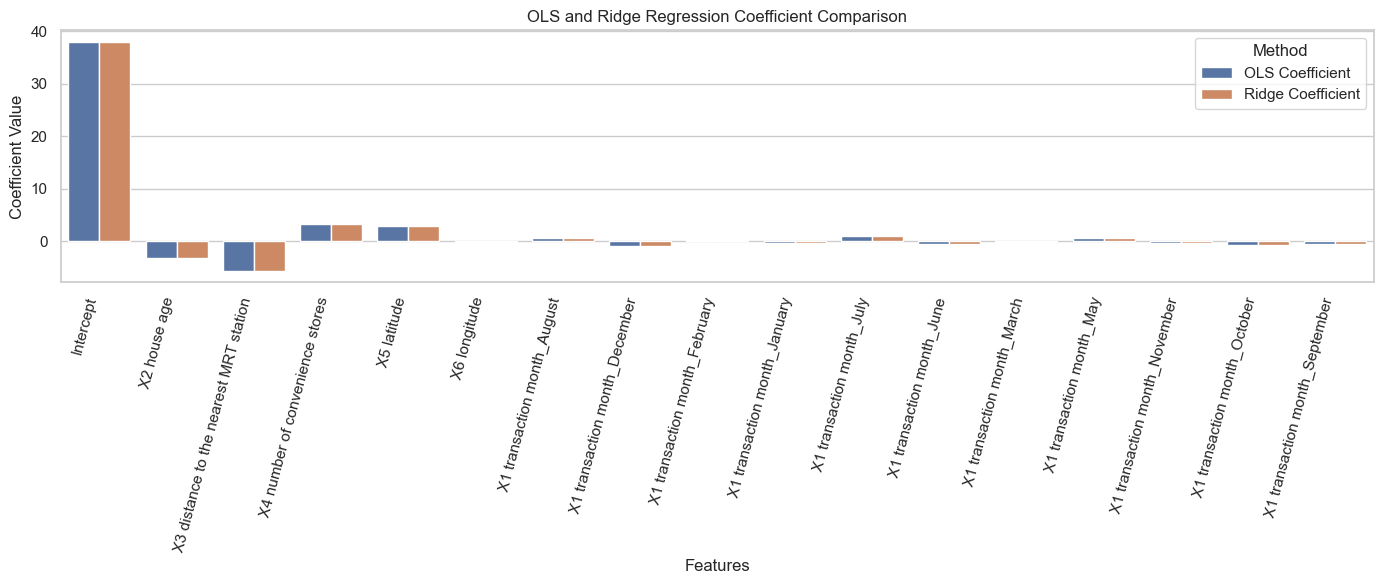

In [25]:
# visualize coefficient comparison

plt.figure(figsize=(14, 6))

coefficient_plot_data = coefficient_comparison.melt(
    id_vars="Feature",
    value_vars=["OLS Coefficient", "Ridge Coefficient"],
    var_name="Method",
    value_name="Coefficient"
)

sns.barplot(
    data=coefficient_plot_data,
    x="Feature",
    y="Coefficient",
    hue="Method"
)

plt.xticks(rotation=75, ha="right")
plt.title("OLS and Ridge Regression Coefficient Comparison")
plt.xlabel("Features")
plt.ylabel("Coefficient Value")
plt.tight_layout()

plt.savefig(
    figures / "ridge_coefficient_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

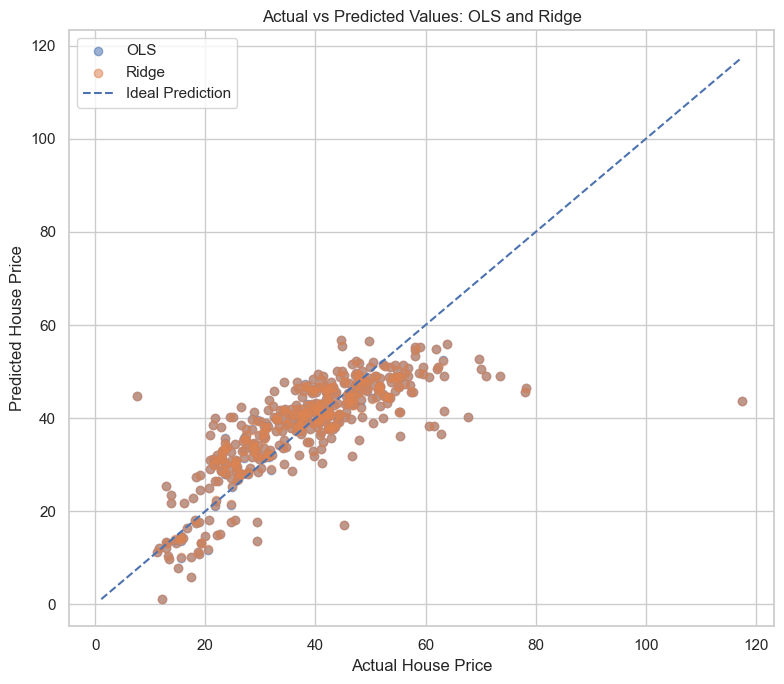

In [27]:
# actual vs predicted values 

plt.figure(figsize=(8, 7))

plt.scatter(
    y,
    y_pred_ols_reference,
    alpha=0.55,
    label="OLS"
)

plt.scatter(
    y,
    y_pred_ridge,
    alpha=0.55,
    label="Ridge"
)

min_value = min(y.min(), y_pred_ols_reference.min(), y_pred_ridge.min())
max_value = max(y.max(), y_pred_ols_reference.max(), y_pred_ridge.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Ideal Prediction"
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted Values: OLS and Ridge")
plt.legend()
plt.tight_layout()

plt.savefig(
    figures / "ridge_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

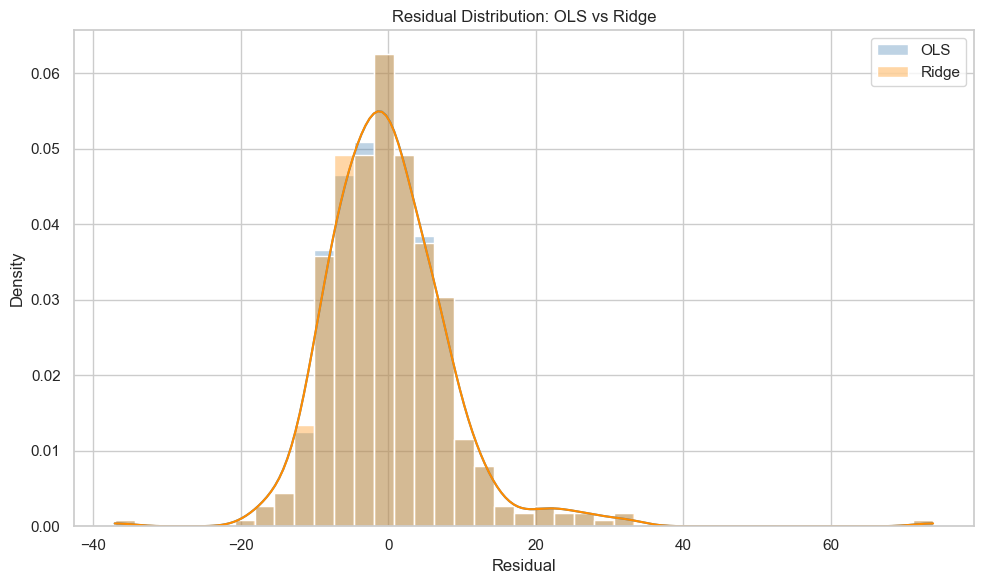

In [29]:
# residual comparison

residuals_ols_reference = y - y_pred_ols_reference

plt.figure(figsize=(10, 6))

sns.histplot(
    residuals_ols_reference,
    color="steelblue",
    label="OLS",
    kde=True,
    stat="density",
    alpha=0.35
)

sns.histplot(
    residuals_ridge,
    color="darkorange",
    label="Ridge",
    kde=True,
    stat="density",
    alpha=0.35
)

plt.title("Residual Distribution: OLS vs Ridge")
plt.xlabel("Residual")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()

plt.savefig(
    figures / "ridge_residual_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
# numerical stability analysis

ridge_system_matrix = (
    x_standardized_design.T @ x_standardized_design
    + lambda_value * penalty_matrix
)

condition_number_design = np.linalg.cond(
    x_standardized_design
)

condition_number_gram = np.linalg.cond(
    x_standardized_design.T @ x_standardized_design
)

condition_number_ridge_system = np.linalg.cond(
    ridge_system_matrix
)

stability_comparison = pd.DataFrame({
    "Matrix": [
        "Standardized Design Matrix",
        "OLS Gram Matrix",
        "Ridge Regularized System"
    ],
    "Condition Number": [
        condition_number_design,
        condition_number_gram,
        condition_number_ridge_system
    ]
})

stability_comparison

,Matrix,Condition Number
0,Standardized Design Matrix,5.749522
1,OLS Gram Matrix,33.057005
2,Ridge Regularized System,32.157589


In [31]:
# ridge diagnostics

residual_norm_ridge = np.linalg.norm(residuals_ridge)

relative_residual_ridge = (
    residual_norm_ridge / np.linalg.norm(y)
)

ridge_optimality_residual = (
    x_standardized_design.T @ residuals_ridge
    - lambda_value * penalty_matrix @ beta_ridge
)

ridge_optimality_error = np.linalg.norm(
    ridge_optimality_residual
)

ridge_diagnostics = pd.DataFrame({
    "Diagnostic": [
        "Lambda",
        "Residual Norm",
        "Relative Residual",
        "Coefficient L2 Norm (excluding intercept)",
        "Condition Number of Design Matrix",
        "Condition Number of Ridge System",
        "Ridge Optimality Error"
    ],
    "Value": [
        lambda_value,
        residual_norm_ridge,
        relative_residual_ridge,
        ridge_coefficient_norm,
        condition_number_design,
        condition_number_ridge_system,
        ridge_optimality_error
    ]
})

ridge_diagnostics

,Diagnostic,Value
0,Lambda,1.000000
1,Residual Norm,176.179239
2,Relative Residual,0.214653
3,Coefficient L2 Norm (excluding intercept),8.049095
4,Condition Number of Design Matrix,5.749522
5,Condition Number of Ridge System,32.157589
6,Ridge Optimality Error,0.000000


In [32]:
# interpret the effect of regularization

if ridge_coefficient_norm < ols_coefficient_norm:
    coefficient_observation = (
        "Ridge Regression reduces the overall coefficient L2 norm."
    )
else:
    coefficient_observation = (
        "The Ridge coefficient norm is not smaller than the OLS norm "
        "for this particular regularization setting."
    )

if condition_number_ridge_system < condition_number_gram:
    stability_observation = (
        "The regularized system has a lower condition number "
        "than the unregularized Gram matrix."
    )
else:
    stability_observation = (
        "The regularized system does not show a lower condition number "
        "for this particular setting."
    )

print("Coefficient observation:")
print(coefficient_observation)

print("\nNumerical stability observation:")
print(stability_observation)

Coefficient observation:
Ridge Regression reduces the overall coefficient L2 norm.

Numerical stability observation:
The regularized system has a lower condition number than the unregularized Gram matrix.


In [33]:
# summary

print("RIDGE REGRESSION SUMMARY")

print(f"Regularization parameter: {lambda_value}")

print("\nOLS Performance:")
for metric, value in ols_metrics.items():
    print(f"{metric}: {value:.6f}")

print("\nRidge Performance:")
for metric, value in ridge_metric_values.items():
    print(f"{metric}: {value:.6f}")

print("\nCoefficient Norms:")
print(f"OLS:   {ols_coefficient_norm:.6f}")
print(f"Ridge: {ridge_coefficient_norm:.6f}")

print("\nCondition Numbers:")
print(f"OLS Gram Matrix: {condition_number_gram:.6e}")
print(f"Ridge System:    {condition_number_ridge_system:.6e}")


RIDGE REGRESSION SUMMARY
Regularization parameter: 1.0

OLS Performance:
MSE: 74.973033
RMSE: 8.658697
MAE: 6.013422
R2: 0.594059

Ridge Performance:
MSE: 74.973730
RMSE: 8.658737
MAE: 6.014307
R2: 0.594055

Coefficient Norms:
OLS:   8.085102
Ridge: 8.049095

Condition Numbers:
OLS Gram Matrix: 3.305701e+01
Ridge System:    3.215759e+01


In [34]:
# export results

ridge_coefficients.to_csv(
    tables / "ridge_coefficients.csv",
    index=False
)

ridge_metrics.to_csv(
    tables / "ridge_metrics.csv",
    index=False
)

performance_comparison.to_csv(
    tables / "ridge_ols_performance_comparison.csv",
    index=False
)

coefficient_comparison.to_csv(
    tables / "ridge_ols_coefficient_comparison.csv",
    index=False
)

coefficient_norm_comparison.to_csv(
    tables / "ridge_coefficient_norm_comparison.csv",
    index=False
)

stability_comparison.to_csv(
    tables / "ridge_stability_comparison.csv",
    index=False
)

ridge_diagnostics.to_csv(
    tables / "ridge_diagnostics.csv",
    index=False
)

prediction_comparison = pd.DataFrame({
    "Actual": y,
    "OLS Predicted": y_pred_ols_reference,
    "Ridge Predicted": y_pred_ridge,
    "OLS Residual": residuals_ols_reference,
    "Ridge Residual": residuals_ridge
})

prediction_comparison.to_csv(
    tables / "ridge_prediction_comparison.csv",
    index=False
)

print("All Ridge Regression results exported successfully.")

All Ridge Regression results exported successfully.


## Experimental Observations

The Ridge Regression implementation introduces an L2 regularization penalty to the least-squares objective function.

The predictor variables are standardized before estimation to ensure that the regularization penalty is applied on a comparable scale.

The intercept is excluded from the penalty matrix.

The initial experiment uses λ = 1.0 to examine the effect of regularization on the regression coefficients, prediction performance and numerical properties of the system.

The comparison with OLS provides an initial assessment of how coefficient shrinkage affects the fitted model.

The optimal regularization parameter is not determined in this experiment. A systematic investigation of coefficient behaviour across different λ values is performed in the next experiment, followed by k-fold cross-validation for selecting an appropriate λ.

## Conclusion

Ridge Regression extends the OLS formulation by introducing an L2 regularization term.

The regularization parameter controls the degree of coefficient shrinkage. As λ increases, the magnitude of the penalized coefficients is generally reduced.

The experiment provides the initial implementation and comparison of Ridge Regression with the revised OLS model.

The next experiment investigates the behaviour of Ridge coefficients over a range of regularization parameters through Ridge Trace analysis.